# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

In [1]:
import urllib.request
import zipfile
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"
base_dir = Path.cwd()
zip_path = base_dir / "realwaste.zip"
extract_dir = base_dir / "RealWaste"

# Download the dataset if it is not already in the workspace
if not zip_path.exists():
    print(f"Downloading dataset from {url}...")
    with urllib.request.urlopen(url, timeout=60) as response:
        zip_path.write_bytes(response.read())
else:
    print(f"Dataset archive already exists at: {zip_path}")

# Extract the archive into the current working directory
if not extract_dir.exists():
    print(f"Extracting archive to {base_dir}...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(base_dir)

    # Some archives extract into a nested folder with a slightly different casing/name
    candidates = sorted(
        [p for p in base_dir.iterdir() if p.is_dir() and "realwaste" in p.name.lower()],
        key=lambda p: len(p.name),
    )
    if candidates:
        extract_dir = candidates[0]

if not extract_dir.exists():
    raise FileNotFoundError(f"Could not find the extracted dataset folder: {extract_dir}")

print(f"Dataset is ready at: {extract_dir}")


Dataset archive already exists at: /home/george/DS/lab_md_5/summertive_waste/realwaste.zip
Dataset is ready at: /home/george/DS/lab_md_5/summertive_waste/RealWaste


### 1.1 Load and Explore the RealWaste Dataset

In [ ]:
# Import necessary libraries
import sys
sys.modules["triton"] = None

import tensorflow as tf
import tensorflow_hub as hub
import tensorflow_text as text
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import random
import pandas as pd

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

I0000 00:00:1792874716.041244   41891 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792874716.409148   41891 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792874718.651707   41891 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/home/george/anaconda3/lib/python3.13/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Dataset path: /home/george/DS/lab_md_5/summertive_waste/RealWaste
Dataset exists: True
Dataset location: /home/george/DS/lab_md_5/summertive_waste/RealWaste
Number of waste categories: 9

Waste categories and sample files:

Cardboard: 461 images
Sample files: ['Cardboard_86.jpg', 'Cardboard_107.jpg', 'Cardboard_370.jpg']

Food Organics: 411 images
Sample files: ['Food Organics_148.jpg', 'Food Organics_107.jpg', 'Food Organics_95.jpg']

Glass: 420 images
Sample files: ['Glass_195.jpg', 'Glass_244.jpg', 'Glass_154.jpg']

Metal: 790 images
Sample files: ['Metal_673.jpg', 'Metal_304.jpg', 'Metal_10.jpg']

Miscellaneous Trash: 495 images
Sample files: ['Miscellaneous Trash_427.jpg', 'Miscellaneous Trash_210.jpg', 'Miscellaneous Trash_270.jpg']

Paper: 500 images
Sample files: ['Paper_439.jpg', 'Paper_409.jpg', 'Paper_495.jpg']

Plastic: 921 images
Sample files: ['Plastic_849.jpg', 'Plastic_679.jpg', 'Plastic_70.jpg']

Textile Trash: 318 images
Sample files: ['Textile Trash_287.jpg', 'Textil

,Category,Image_Count,Percentage
6,Plastic,921,19.381313
3,Metal,790,16.624579
5,Paper,500,10.521886
4,Miscellaneous Trash,495,10.416667
0,Cardboard,461,9.701178
8,Vegetation,436,9.175084
2,Glass,420,8.838384
1,Food Organics,411,8.648990
7,Textile Trash,318,6.691919


Total images: 4752


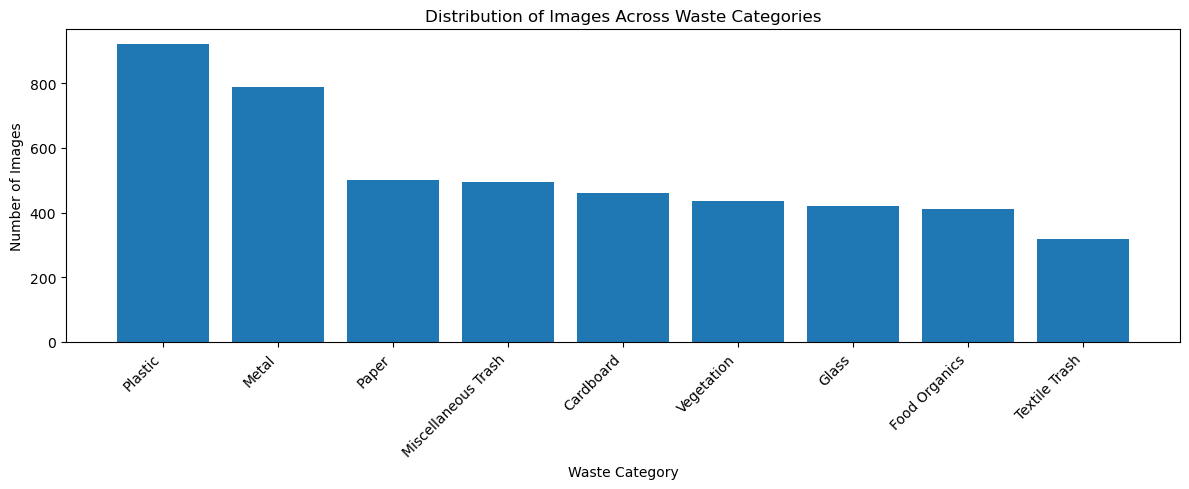

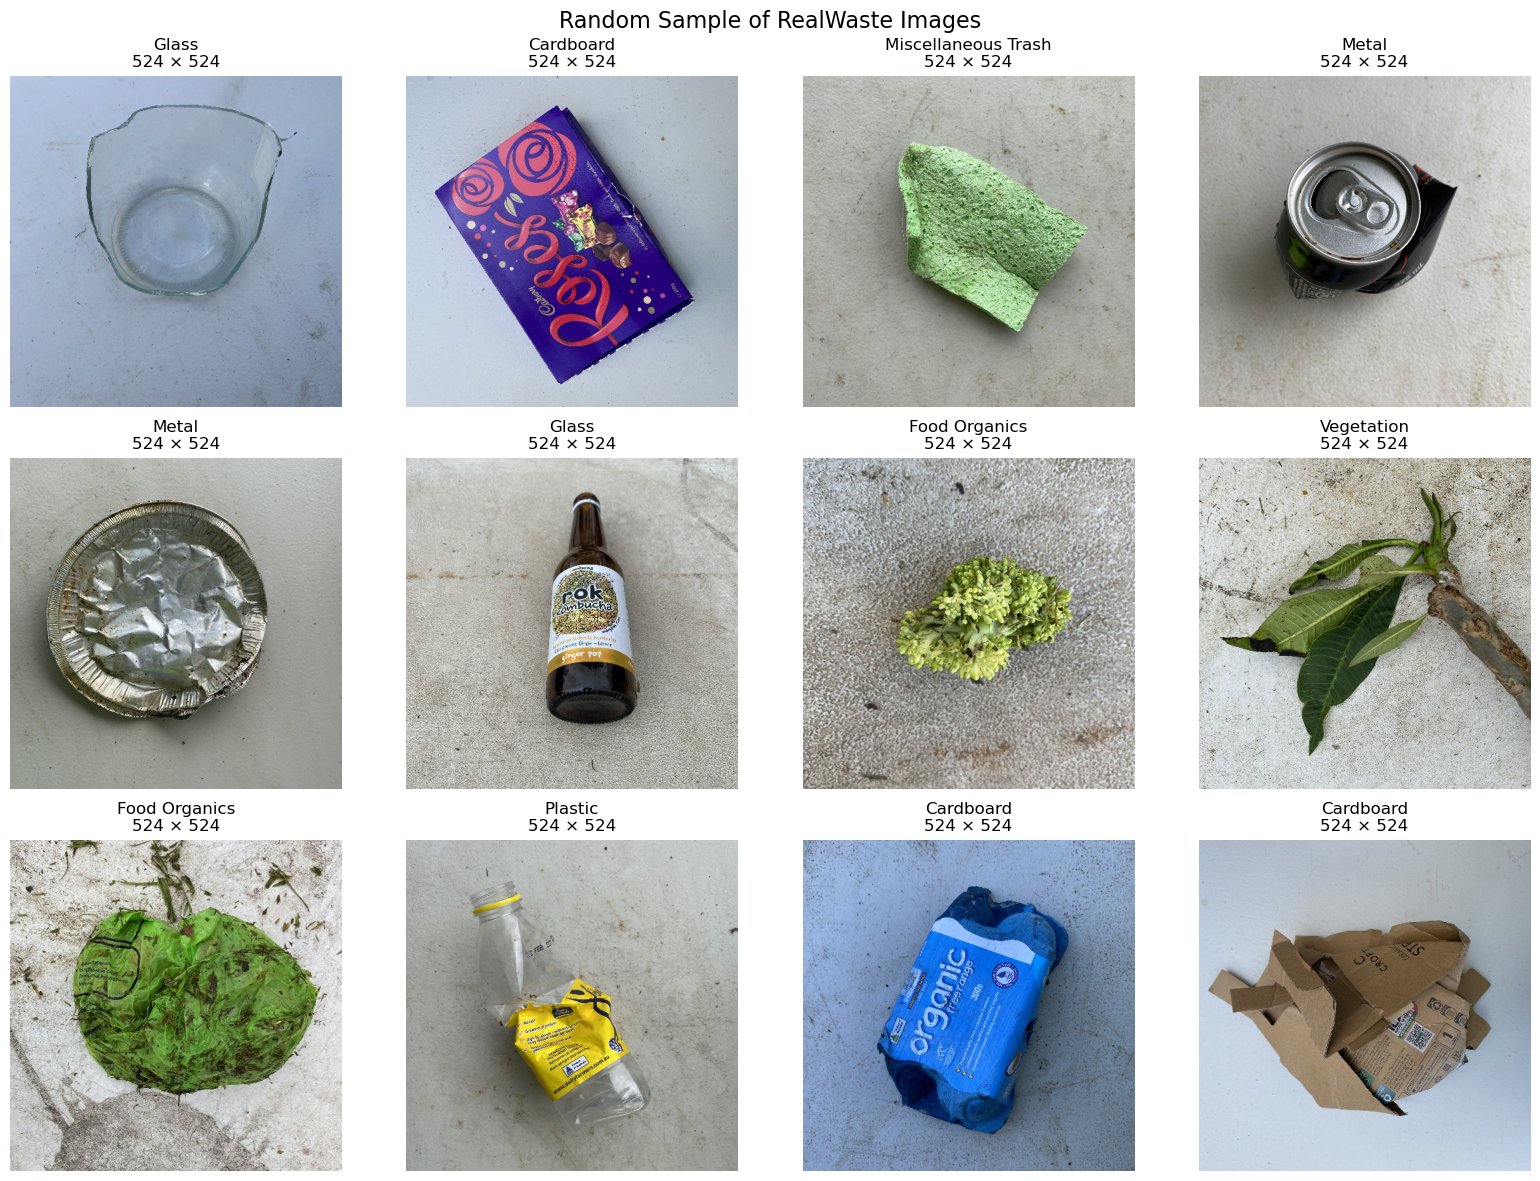


Image characteristics for the sampled images:


,Category,Filename,Width,Height,Aspect_Ratio,Brightness_Mean,File_Size_KB
0,Glass,Glass_149.jpg,524,524,1.0,164.88,76.36
1,Cardboard,Cardboard_214.jpg,524,524,1.0,156.89,117.41
2,Miscellaneous Trash,Miscellaneous Trash_155.jpg,524,524,1.0,160.18,136.57
3,Metal,Metal_656.jpg,524,524,1.0,159.72,99.94
4,Metal,Metal_481.jpg,524,524,1.0,140.50,131.07
5,Glass,Glass_92.jpg,524,524,1.0,164.82,167.03
6,Food Organics,Food Organics_271.jpg,524,524,1.0,153.26,180.93
7,Vegetation,Vegetation_415.jpg,524,524,1.0,161.29,193.83
8,Food Organics,Food Organics_359.jpg,524,524,1.0,153.64,191.01
9,Plastic,Plastic_431.jpg,524,524,1.0,156.51,120.53



Resolution summary:


,Width,Height,Aspect_Ratio
count,12.0,12.0,12.0
mean,524.0,524.0,1.0
std,0.0,0.0,0.0
min,524.0,524.0,1.0
25%,524.0,524.0,1.0
50%,524.0,524.0,1.0
75%,524.0,524.0,1.0
max,524.0,524.0,1.0



Image quality and background observations:
- Review the displayed images for blur, poor lighting, occlusion, and compression artifacts.
- Check whether backgrounds are consistent or contain clutter, bins, floors, or other objects.
- Brightness is a basic pixel-intensity measure; it does not by itself determine image quality.


In [3]:
# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

# Your code here
# TODO: Load and explore the RealWaste dataset

import os
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageStat

# Set the dataset path
from pathlib import Path

DATASET_PATH = Path("RealWaste")

print("Dataset path:", DATASET_PATH.resolve())
print("Dataset exists:", DATASET_PATH.exists())

# Check whether the dataset folder exists
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATASET_PATH.resolve()}\n"
        "Place the RealWaste folder in the same directory as this notebook."
    )

# 1. Explore dataset structure
class_folders = sorted(
    folder for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
)

print("Dataset location:", DATASET_PATH.resolve())
print("Number of waste categories:", len(class_folders))
print("\nWaste categories and sample files:")

for folder in class_folders:
    image_files = [
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    print(f"\n{folder.name}: {len(image_files)} images")
    print("Sample files:", [f.name for f in image_files[:3]])

# 2. Calculate the distribution of waste categories
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
category_counts = {}

for folder in class_folders:
    count = sum(
        1 for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    )
    category_counts[folder.name] = count

category_distribution = pd.DataFrame({
    "Category": list(category_counts.keys()),
    "Image_Count": list(category_counts.values())
})

total_images = category_distribution["Image_Count"].sum()

category_distribution["Percentage"] = (
    category_distribution["Image_Count"] / total_images * 100
    if total_images > 0 else 0
)

category_distribution = category_distribution.sort_values(
    "Image_Count", ascending=False
)

print("\nCategory distribution:")
display(category_distribution)

print(f"Total images: {total_images}")

# Visualize category distribution
plt.figure(figsize=(12, 5))
plt.bar(
    category_distribution["Category"],
    category_distribution["Image_Count"]
)
plt.title("Distribution of Images Across Waste Categories")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3. Inspect image characteristics
# Randomly sample images from the dataset
all_images = [
    file
    for folder in class_folders
    for file in folder.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

if not all_images:
    print("No supported image files were found.")
else:
    random.seed(42)
    sample_size = min(12, len(all_images))
    sampled_images = random.sample(all_images, sample_size)

    image_details = []
    fig, axes = plt.subplots(
        nrows=(sample_size + 3) // 4,
        ncols=4,
        figsize=(16, 4 * ((sample_size + 3) // 4))
    )
    axes = np.array(axes).reshape(-1)

    for i, image_path in enumerate(sampled_images):
        try:
            with Image.open(image_path) as img:
                img_rgb = img.convert("RGB")
                width, height = img.size
                mean_brightness = np.mean(
                    ImageStat.Stat(img_rgb).mean
                )
                file_size_kb = image_path.stat().st_size / 1024

                image_details.append({
                    "Category": image_path.parent.name,
                    "Filename": image_path.name,
                    "Width": width,
                    "Height": height,
                    "Aspect_Ratio": round(width / height, 2),
                    "Brightness_Mean": round(mean_brightness, 2),
                    "File_Size_KB": round(file_size_kb, 2)
                })

                axes[i].imshow(img_rgb)
                axes[i].set_title(
                    f"{image_path.parent.name}\n{width} × {height}"
                )
                axes[i].axis("off")

        except Exception as error:
            print(f"Could not read {image_path}: {error}")
            axes[i].axis("off")

    for j in range(sample_size, len(axes)):
        axes[j].axis("off")

    plt.suptitle("Random Sample of RealWaste Images", fontsize=16)
    plt.tight_layout()
    plt.show()

    # Summarize image characteristics
    image_characteristics = pd.DataFrame(image_details)

    print("\nImage characteristics for the sampled images:")
    display(image_characteristics)

    print("\nResolution summary:")
    display(
        image_characteristics[["Width", "Height", "Aspect_Ratio"]]
        .describe()
        .round(2)
    )

    print("\nImage quality and background observations:")
    print(
        "- Review the displayed images for blur, poor lighting, "
        "occlusion, and compression artifacts."
    )
    print(
        "- Check whether backgrounds are consistent or contain "
        "clutter, bins, floors, or other objects."
    )
    print(
        "- Brightness is a basic pixel-intensity measure; it does not "
        "by itself determine image quality."
    )

### 1.2 Explore Text Datasets

In [4]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories

# Your code here

df = pd.read_csv('waste_descriptions.csv')
print(df.shape)
print("\nCategory distribution:")
print(df['category'].value_counts())
# print(df.head())
print("\nSample descriptions:")
for cate in df['category'].unique():
    sample_idx = df[df['category'] == cate].index[0]
    print(f"\n{cate.upper()}: {df.loc[sample_idx, 'description']}")





(5000, 5)

Category distribution:
category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64

Sample descriptions:

TEXTILE TRASH: soiled silver tablecloth

GLASS: folded glass bottle leaking

FOOD ORGANICS: large Supermarket vegetable waste with food residue

PLASTIC: wrinkled pink takeout container with product remaining

VEGETATION: clean red grass clippings

CARDBOARD: Designer egg carton

METAL: wrinkled metal cutlery with food residue

PAPER: wrinkled newspaper

MISCELLANEOUS TRASH: gold cigarette butt


In [12]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language

# Your code here
policy_df = pd.read_json('waste_policy_documents.json')
print(policy_df.shape)
print("\nSample policy documents:")
print(policy_df.head())
print("\nPolicy document categories:")
print(policy_df['categories_covered'].value_counts())



(14, 6)

Sample policy documents:
   policy_id                         policy_type categories_covered  \
0          1  Textile Trash Recycling Guidelines    [Textile Trash]   
1          2          Glass Recycling Guidelines            [Glass]   
2          3  Food Organics Recycling Guidelines    [Food Organics]   
3          4        Plastic Recycling Guidelines          [Plastic]   
4          5     Vegetation Recycling Guidelines       [Vegetation]   

  effective_date                                      document_text  \
0     2023-11-04  TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...   
1     2023-01-24  GLASS RECYCLING GUIDELINES\n\nAcceptable Items...   
2     2023-05-08  FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...   
3     2023-04-05  PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...   
4     2023-12-04  VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...   

  jurisdiction  
0   Metro City  
1   Metro City  
2   Metro City  
3   Metro City  
4   Metro City  

Policy do

### 1.3 Create Data Pipelines

In [13]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('RealWaste')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [14]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

# Your code here
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords,wordnet
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from nltk import pos_tag





nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')


# Initialize lemmatizer and stopwords
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Lemmatizer relies of part of speech to help
def get_wordnet_pos(treebank_tag):
  '''
  Translate nltk POS to wordnet tags
  '''
  if treebank_tag.startswith('J'):
      return wordnet.ADJ
  elif treebank_tag.startswith('V'):
      return wordnet.VERB
  elif treebank_tag.startswith('N'):
      return wordnet.NOUN
  elif treebank_tag.startswith('R'):
      return wordnet.ADV
  else:
      return wordnet.NOUN


def basic_preprocess(text):
   """Basic preprocessing function for text."""
   # Convert to lowercase
   text = text.lower()
  
   # Remove special characters and numbers
   text = re.sub(r'[^a-zA-Z\s]', '', text)
  
   # Return cleaned text
   return text


def advanced_preprocess(text):
   """Advanced preprocessing with tokenization, stopword removal, and lemmatization."""
   # Basic cleaning
   text = basic_preprocess(text)
  
   # Tokenize
   tokens = nltk.word_tokenize(text)
  
   # Tag with pos
   tokens_tagged = pos_tag(tokens)
   pos_tokens = [(word[0], get_wordnet_pos(word[1])) for word in tokens_tagged]
  
   # Remove stopwords and lemmatize
   cleaned_tokens = [lemmatizer.lemmatize(token[0], token[1]) for token in pos_tokens if token[0] not in stop_words and len(token[0]) > 1]
  
   # Return cleaned tokens
   return ' '.join(cleaned_tokens)


# Apply preprocessing to the dataset
df['cleaned_text'] = df['description'].apply(basic_preprocess)
df['lemmatized_text'] = df['description'].apply(advanced_preprocess)


# Show the preprocessing results for a sample ticket
sample_idx = 1
print(f"Original: {df.loc[sample_idx, 'description']}")
print(f"Cleaned: {df.loc[sample_idx, 'cleaned_text']}")
print(f"Lemmatized: {df.loc[sample_idx, 'lemmatized_text']}")



[nltk_data] Downloading package punkt to /home/george/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /home/george/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/george/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Original: folded glass bottle leaking
Cleaned: folded glass bottle leaking
Lemmatized: folded glass bottle leak


In [15]:
X = df['lemmatized_text']
y = df['category']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42,stratify=y)  # Ensure balanced classes in both sets



print(f"Training set size: {len(X_train)}")
print(f"Testing set size: {len(X_test)}")
print(f"Class distribution in training set: \n{y_train.value_counts()}")
print(f"Class distribution in testing set: \n{y_test.value_counts()}")

Training set size: 4000
Testing set size: 1000
Class distribution in training set: 
category
Vegetation             480
Textile Trash          469
Cardboard              467
Miscellaneous Trash    462
Plastic                455
Glass                  441
Food Organics          414
Metal                  407
Paper                  405
Name: count, dtype: int64
Class distribution in testing set: 
category
Vegetation             120
Cardboard              117
Textile Trash          117
Miscellaneous Trash    116
Plastic                114
Glass                  110
Food Organics          104
Paper                  101
Metal                  101
Name: count, dtype: int64


In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Bag of Words vectorizer
count_vectorizer = CountVectorizer(
   preprocessor=advanced_preprocess,
   lowercase=False,  # Already done in preprocessing
   min_df=2,  # Ignore terms that appear in fewer than 2 documents
   max_df=0.95, # Ignore terms that appear in more than 95% of documents
   ngram_range=(1, 2) # Include both single words and pairs of consecutive words
)


# TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
   preprocessor=advanced_preprocess,
   lowercase=False,
   min_df=2,
   max_df=0.95,
   ngram_range=(1, 2)
)


# Apply vectorizers to training data
X_train_counts = count_vectorizer.fit_transform(X_train)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)


# Get feature information
count_features = count_vectorizer.get_feature_names_out()
tfidf_features = tfidf_vectorizer.get_feature_names_out()


print(f"Bag of Words features: {len(count_features)}")
print(f"TF-IDF features: {len(tfidf_features)}")
print(f"Sample BoW features: {count_features[:10]}")
print(f"Sample TF-IDF features (including bigrams): {[f for f in tfidf_features[:20] if ' ' in f][:5]}")

Bag of Words features: 2700
TF-IDF features: 2700
Sample BoW features: ['aerosol' 'aluminum' 'aluminum foil' 'apple' 'apple core' 'appliance'
 'appliance box' 'artisanal' 'artisanal battery' 'artisanal branch']
Sample TF-IDF features (including bigrams): ['aluminum foil', 'apple core', 'appliance box', 'artisanal battery', 'artisanal branch']


In [17]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

# Your code here
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# The 9 waste categories the policies refer to (same names as the text dataset)
WASTE_CATEGORIES = sorted(df['category'].unique())


def split_into_sections(document_text):
    """Split a policy document into (heading, body) sections.

    Documents use a title line, then blocks separated by blank lines where the
    first line of each block is a heading ending in ':' (e.g. 'Acceptable Items:',
    'GLASS GUIDELINES:').
    """
    blocks = [b.strip() for b in re.split(r'\n\s*\n', document_text) if b.strip()]
    title = blocks[0]
    sections = []
    for block in blocks[1:]:
        lines = block.split('\n')
        heading = lines[0].rstrip(':').strip()
        body = '\n'.join(lines[1:]).strip()
        sections.append((heading, body))
    return title, sections


def section_category(heading, doc_categories):
    """Return the waste category a section is about.

    Multi-category documents have headings like 'PLASTIC GUIDELINES'; single
    category documents inherit the document's only category. Sections that apply
    to everything (e.g. 'GENERAL REQUIREMENTS') return 'General'.
    """
    for cat in WASTE_CATEGORIES:
        if heading.upper().startswith(cat.upper()):
            return cat
    if len(doc_categories) == 1:
        return doc_categories[0]
    return 'General'


# 1. Document preprocessing: chunk every policy into section-level passages
policy_chunks = []
for _, row in policy_df.iterrows():
    title, sections = split_into_sections(row['document_text'])
    for heading, body in sections:
        category = section_category(heading, row['categories_covered'])
        policy_chunks.append({
            'chunk_id': len(policy_chunks),
            'policy_id': row['policy_id'],
            'policy_type': row['policy_type'],
            'effective_date': row['effective_date'],
            'jurisdiction': row['jurisdiction'],
            'category': category,
            'section': heading,
            # Prefix the title/category so a chunk is self-describing when retrieved
            'text': f"{row['policy_type']} - {heading} ({category}):\n{body}",
        })

chunks_df = pd.DataFrame(policy_chunks)
chunks_df['clean_text'] = chunks_df['text'].apply(advanced_preprocess)

print(f"Policy documents: {len(policy_df)}")
print(f"Section chunks created: {len(chunks_df)}")
print("\nChunks per category:")
print(chunks_df['category'].value_counts())
print("\nChunks per section type:")
print(chunks_df['section'].value_counts().head(10))

# 2. Create embeddings for retrieval
# TF-IDF vectors (unigrams + bigrams) over the lemmatized chunk text. The corpus
# is small and domain-specific, so sparse lexical embeddings work well and need
# no model download; queries go through the same preprocessing.
rag_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
chunk_embeddings = rag_vectorizer.fit_transform(chunks_df['clean_text'])
print(f"\nChunk embedding matrix: {chunk_embeddings.shape}")


def retrieve_policy_chunks(query, category=None, top_k=3):
    """Return the top_k most relevant policy chunks for a query.

    If a category is given, chunks for that category (and 'General' chunks) are
    preferred by a small score boost, so retrieval stays on-topic even when the
    query wording is vague.
    """
    query_vec = rag_vectorizer.transform([advanced_preprocess(query)])
    scores = cosine_similarity(query_vec, chunk_embeddings).ravel()
    if category is not None:
        scores = scores + 0.2 * (chunks_df['category'] == category).values \
                        + 0.05 * (chunks_df['category'] == 'General').values
    top_idx = scores.argsort()[::-1][:top_k]
    results = chunks_df.iloc[top_idx][['policy_type', 'category', 'section', 'text']].copy()
    results['score'] = scores[top_idx]
    return results


# Quick sanity check of the retriever
for q, cat in [("how do I prepare glass jars for recycling", "Glass"),
               ("where do batteries go", None),
               ("greasy pizza box", "Cardboard")]:
    print(f"\nQuery: '{q}' (category={cat})")
    for _, r in retrieve_policy_chunks(q, category=cat).iterrows():
        print(f"  [{r['score']:.3f}] {r['policy_type']} | {r['section']} ({r['category']})")

Policy documents: 14
Section chunks created: 67

Chunks per category:
category
Metal                  8
Vegetation             8
Glass                  7
Textile Trash          7
Cardboard              7
Plastic                7
Miscellaneous Trash    7
Food Organics          6
Paper                  5
General                5
Name: count, dtype: int64

Chunks per section type:
section
Benefits                          9
Acceptable Items                  8
Non-Acceptable Items              8
Collection Method                 8
Preparation Instructions          8
GENERAL REQUIREMENTS              5
METAL GUIDELINES                  3
VEGETATION GUIDELINES             3
MISCELLANEOUS TRASH GUIDELINES    3
GLASS GUIDELINES                  2
Name: count, dtype: int64

Chunk embedding matrix: (67, 882)

Query: 'how do I prepare glass jars for recycling' (category=Glass)
  [0.671] Glass Recycling Guidelines | Acceptable Items (Glass)
  [0.608] Residential Recycling Rules | GLASS GUIDELINES 

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Validation images: 475 | Test images: 475
Batch shape: (32, 224, 224, 3) | pixel range: 0.0 - 255.0


W0000 00:00:1792874836.362862   46897 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.



Class weights:
  Cardboard              n= 387  weight=1.09
  Food Organics          n= 327  weight=1.29
  Glass                  n= 342  weight=1.24
  Metal                  n= 617  weight=0.68
  Miscellaneous Trash    n= 403  weight=1.05
  Paper                  n= 381  weight=1.11
  Plastic                n= 742  weight=0.57
  Textile Trash          n= 243  weight=1.74
  Vegetation             n= 360  weight=1.17


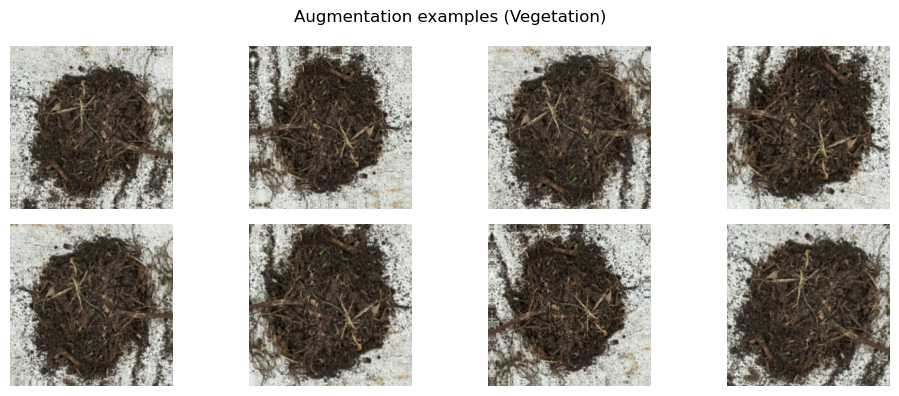

In [ ]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Your code here
from tensorflow.keras import layers

val_full_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True
)
val_images, val_labels = [], []
for x, y in val_full_ds:          # a single pass -> a single, fixed ordering
    val_images.append(tf.cast(x, tf.uint8).numpy())   # uint8 keeps memory low
    val_labels.append(y.numpy())
val_images = np.concatenate(val_images)
val_labels = np.concatenate(val_labels)

n_test = len(val_images) // 2
test_images, test_labels = val_images[:n_test], val_labels[:n_test]
val_images, val_labels = val_images[n_test:], val_labels[n_test:]

def to_dataset(images, labels):
    ds = tf.data.Dataset.from_tensor_slices((images, labels)).batch(BATCH_SIZE)
    return ds.map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

validation_ds = to_dataset(val_images, val_labels)
test_dataset = to_dataset(test_images, test_labels)
print(f"Validation images: {len(val_images)} | Test images: {len(test_images)}")

data_augmentation = Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

# --- 3. Pixel scaling ---------------------------------------------------------

for images, labels in train_ds.take(1):
    print("Batch shape:", images.shape, "| pixel range:",
          float(tf.reduce_min(images)), "-", float(tf.reduce_max(images)))

# --- 4. Class weights to counter class imbalance ------------------------------

train_label_idx = np.concatenate([np.argmax(y, axis=1) for _, y in train_ds])
class_counts = np.bincount(train_label_idx, minlength=num_classes)
class_weight = {i: len(train_label_idx) / (num_classes * c) for i, c in enumerate(class_counts)}
print("\nClass weights:")
for i, name in enumerate(class_names):
    print(f"  {name:22s} n={class_counts[i]:4d}  weight={class_weight[i]:.2f}")

# Visualise augmentation on one training image
sample_image = images[0]
plt.figure(figsize=(10, 4))
for i in range(8):
    augmented = data_augmentation(tf.expand_dims(sample_image, 0), training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(tf.cast(augmented[0], tf.uint8))
    plt.axis("off")
plt.suptitle(f"Augmentation examples ({class_names[np.argmax(labels[0])]})")
plt.tight_layout()
plt.show()

### 2.2 Implement CNN Model with Transfer Learning

In [ ]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Your code here
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import regularizers


base_model = EfficientNetB0(
    include_top=False,            # drop the 1000-class ImageNet head
    weights="imagenet",
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
)
base_model.trainable = False      # stage 1: feature extraction only


def build_cnn(base, dropout_rate=0.3, l2=1e-4):
    """Augmentation -> frozen EfficientNet -> pooled features -> 9-class softmax."""
    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = data_augmentation(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation="softmax",
                           kernel_regularizer=regularizers.l2(l2))(x)
    return keras.Model(inputs, outputs, name="waste_cnn")


cnn_model = build_cnn(base_model)

# Categorical cross-entropy because labels are one-hot (label_mode='categorical').
# Label smoothing slightly reduces over-confidence on visually similar classes.
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=2, name="top2_acc")],
)
cnn_model.summary()

Model: "waste_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,066,220 (15.51 MB)

 Trainable params: 14,089 (55.04 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

### 2.3 Train and Evaluate the Model

Epoch 1/3


/home/george/anaconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.5295 - loss: 1.6586 - top2_acc: 0.7062 - val_accuracy: 0.7242 - val_loss: 1.1784 - val_top2_acc: 0.8779 - learning_rate: 0.0010
Epoch 2/3
119/119 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.6904 - loss: 1.2091 - top2_acc: 0.8511 - val_accuracy: 0.7642 - val_loss: 1.0315 - val_top2_acc: 0.9116 - learning_rate: 0.0010
Epoch 3/3
119/119 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.7441 - loss: 1.1121 - top2_acc: 0.8819 - val_accuracy: 0.7726 - val_loss: 1.0159 - val_top2_acc: 0.9242 - learning_rate: 0.0010


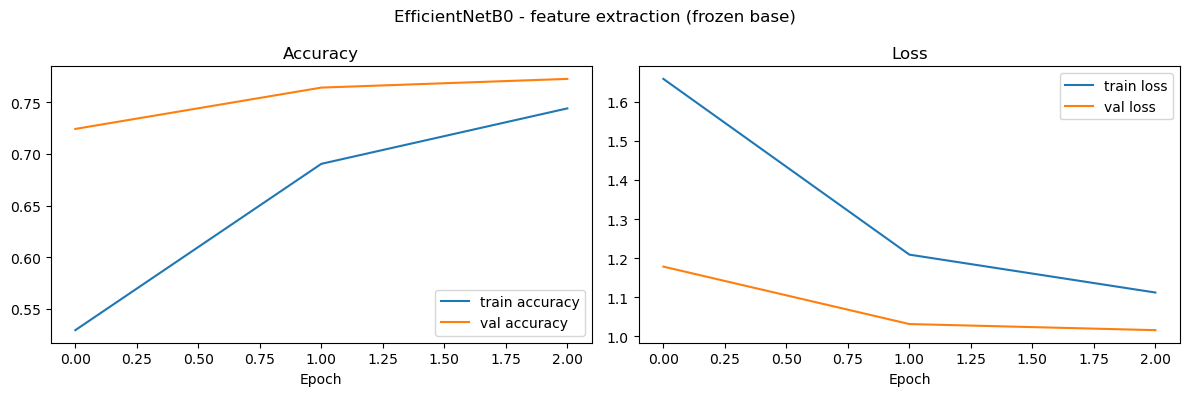

Best epoch: 3 | val_accuracy=0.773 | train_accuracy=0.744


In [ ]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Your code here
INITIAL_EPOCHS = 3

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint("waste_cnn_best.keras", monitor="val_loss", save_best_only=True),
]

history = cnn_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)


def plot_history(histories, title):
    """Plot accuracy and loss curves; accepts one or more History objects in sequence."""
    hist = {k: sum((h.history[k] for h in histories), []) for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(hist[metric], label=f"train {metric}")
        ax.plot(hist[f"val_{metric}"], label=f"val {metric}")
        if len(histories) > 1:
            ax.axvline(len(histories[0].history["loss"]) - 0.5, color="gray", linestyle="--", label="start fine-tuning")
        ax.set_xlabel("Epoch")
        ax.set_title(metric.capitalize())
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history([history], "EfficientNetB0 - feature extraction (frozen base)")
best_epoch = int(np.argmin(history.history["val_loss"]))
print(f"Best epoch: {best_epoch + 1} | val_accuracy={history.history['val_accuracy'][best_epoch]:.3f} "
      f"| train_accuracy={history.history['accuracy'][best_epoch]:.3f}")

Frozen EfficientNetB0
  Test accuracy: 0.785 | Top-2 accuracy: 0.891 | Loss: 1.038

                     precision    recall  f1-score   support

          Cardboard      0.582     0.907     0.709        43
      Food Organics      0.800     0.889     0.842        36
              Glass      0.733     0.846     0.786        39
              Metal      0.922     0.772     0.840        92
Miscellaneous Trash      0.765     0.464     0.578        56
              Paper      0.783     0.783     0.783        60
            Plastic      0.795     0.785     0.790        79
      Textile Trash      0.810     0.872     0.840        39
         Vegetation      0.906     0.935     0.921        31

           accuracy                          0.785       475
          macro avg      0.788     0.806     0.788       475
       weighted avg      0.799     0.785     0.783       475



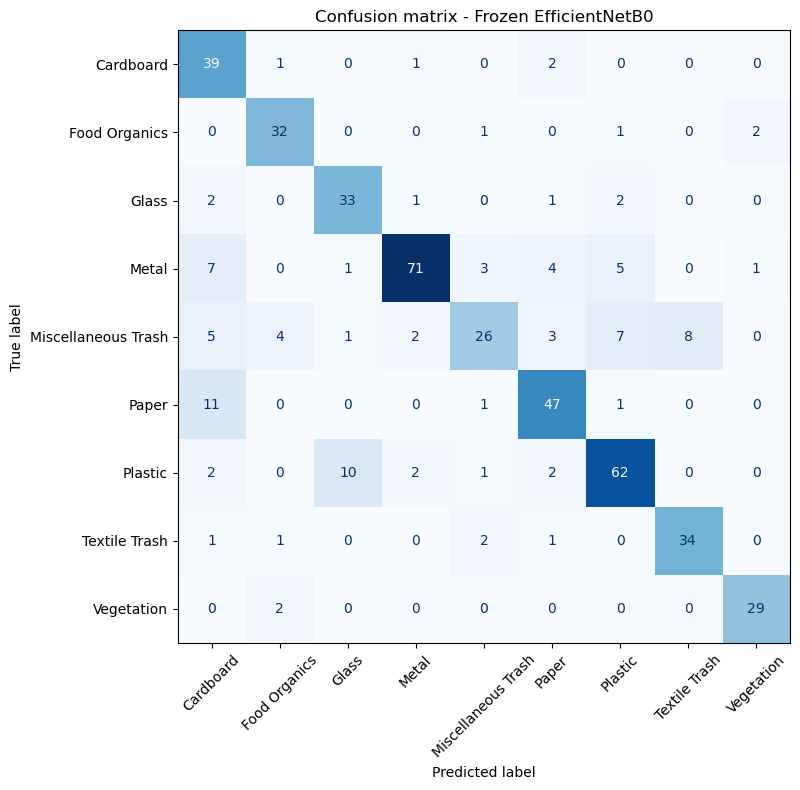

Most common confusions (true -> predicted):
  Paper                  -> Cardboard              11
  Plastic                -> Glass                  10
  Miscellaneous Trash    -> Textile Trash          8
  Miscellaneous Trash    -> Plastic                7
  Metal                  -> Cardboard              7
  Miscellaneous Trash    -> Cardboard              5


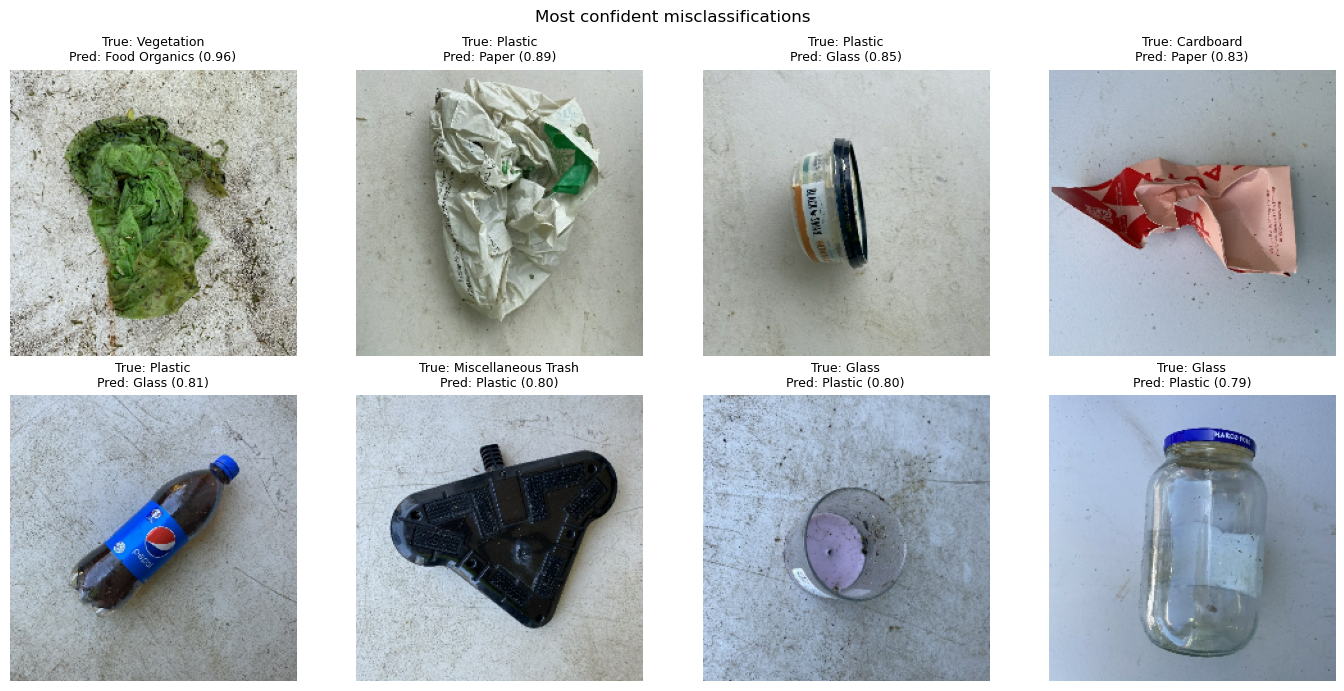

In [16]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_test_true = np.argmax(test_labels, axis=1)


def evaluate_cnn(model, title):
    """Report test accuracy, per-class metrics, confusion matrix and top confusions."""
    test_loss, test_acc, test_top2 = model.evaluate(test_dataset, verbose=0)
    probs = model.predict(test_dataset, verbose=0)
    y_pred = np.argmax(probs, axis=1)

    print(f"{title}\n  Test accuracy: {test_acc:.3f} | Top-2 accuracy: {test_top2:.3f} | Loss: {test_loss:.3f}\n")
    print(classification_report(y_test_true, y_pred, target_names=class_names, digits=3))

    cm = confusion_matrix(y_test_true, y_pred)
    fig, ax = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(f"Confusion matrix - {title}")
    plt.tight_layout()
    plt.show()

    # Most frequent off-diagonal confusions
    off_diag = [(cm[i, j], class_names[i], class_names[j])
                for i in range(num_classes) for j in range(num_classes) if i != j and cm[i, j] > 0]
    print("Most common confusions (true -> predicted):")
    for count, t, p in sorted(off_diag, reverse=True)[:6]:
        print(f"  {t:22s} -> {p:22s} {count}")
    return test_acc, probs, y_pred


frozen_test_acc, frozen_probs, frozen_pred = evaluate_cnn(cnn_model, "Frozen EfficientNetB0")

# Show the most confident mistakes - these reveal *why* the model fails
# (e.g. shared materials, clutter, lighting) rather than just how often.
wrong = np.where(frozen_pred != y_test_true)[0]
wrong = wrong[np.argsort(-frozen_probs[wrong].max(axis=1))][:8]
plt.figure(figsize=(14, 7))
for k, idx in enumerate(wrong):
    plt.subplot(2, 4, k + 1)
    plt.imshow(test_images[idx])
    plt.title(f"True: {class_names[y_test_true[idx]]}\nPred: {class_names[frozen_pred[idx]]} "
              f"({frozen_probs[idx].max():.2f})", fontsize=9)
    plt.axis("off")
plt.suptitle("Most confident misclassifications")
plt.tight_layout()
plt.show()

### 2.4 Fine-tune the Model

Trainable layers in base: 32 / 238
Epoch 1/3


/home/george/anaconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.7741 - loss: 1.0302 - top2_acc: 0.9093 - val_accuracy: 0.7895 - val_loss: 1.0322 - val_top2_acc: 0.9263 - learning_rate: 1.0000e-05
Epoch 2/3
119/119 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.7806 - loss: 1.0042 - top2_acc: 0.9166 - val_accuracy: 0.7874 - val_loss: 1.0332 - val_top2_acc: 0.9284 - learning_rate: 1.0000e-05
Epoch 3/3
119/119 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.7946 - loss: 0.9954 - top2_acc: 0.9179 - val_accuracy: 0.7916 - val_loss: 1.0375 - val_top2_acc: 0.9284 - learning_rate: 3.0000e-06


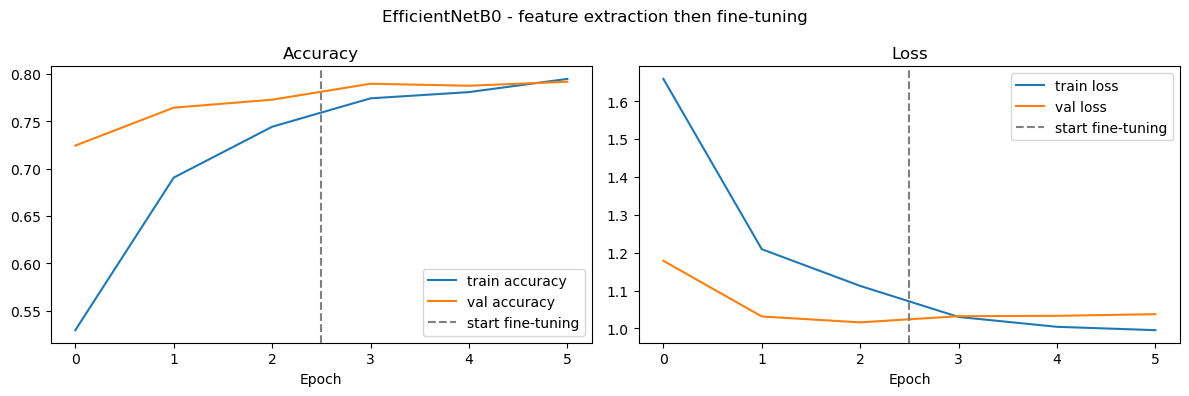

Fine-tuned EfficientNetB0
  Test accuracy: 0.785 | Top-2 accuracy: 0.899 | Loss: 1.048

                     precision    recall  f1-score   support

          Cardboard      0.565     0.907     0.696        43
      Food Organics      0.805     0.917     0.857        36
              Glass      0.717     0.846     0.776        39
              Metal      0.923     0.783     0.847        92
Miscellaneous Trash      0.758     0.446     0.562        56
              Paper      0.821     0.767     0.793        60
            Plastic      0.795     0.785     0.790        79
      Textile Trash      0.829     0.872     0.850        39
         Vegetation      0.879     0.935     0.906        31

           accuracy                          0.785       475
          macro avg      0.788     0.806     0.786       475
       weighted avg      0.801     0.785     0.783       475



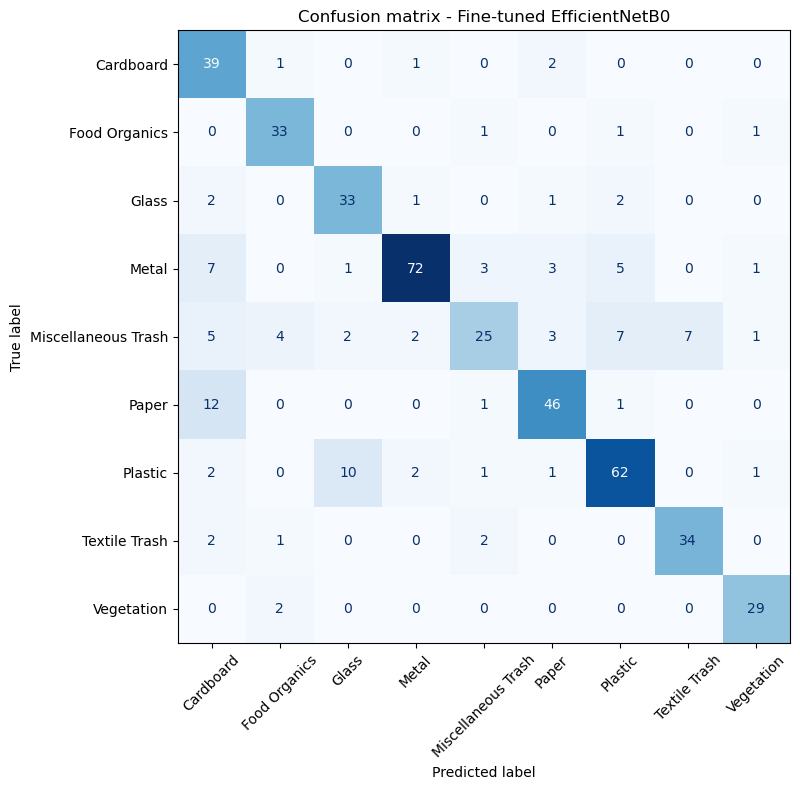

Most common confusions (true -> predicted):
  Paper                  -> Cardboard              12
  Plastic                -> Glass                  10
  Miscellaneous Trash    -> Textile Trash          7
  Miscellaneous Trash    -> Plastic                7
  Metal                  -> Cardboard              7
  Miscellaneous Trash    -> Cardboard              5

Test accuracy: frozen = 0.785 -> fine-tuned = 0.785 (+0.000)
Validation accuracy: frozen = 0.773 -> fine-tuned = 0.789
Saved model to waste_cnn_final.keras


In [ ]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Your code here
_, frozen_val_acc, _ = cnn_model.evaluate(validation_ds, verbose=0)

FINE_TUNE_AT = len(base_model.layers) - 40      # unfreeze roughly the last 2 blocks
base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

for layer in base_model.layers[FINE_TUNE_AT:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(f"Trainable layers in base: {sum(l.trainable for l in base_model.layers)} / {len(base_model.layers)}")


cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=2, name="top2_acc")],
)

FINE_TUNE_EPOCHS = 3
history_fine = cnn_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weight,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-7),
    ],
)

plot_history([history, history_fine], "EfficientNetB0 - feature extraction then fine-tuning")

fine_test_acc, fine_probs, fine_pred = evaluate_cnn(cnn_model, "Fine-tuned EfficientNetB0")
print(f"\nTest accuracy: frozen = {frozen_test_acc:.3f} -> fine-tuned = {fine_test_acc:.3f} "
      f"({fine_test_acc - frozen_test_acc:+.3f})")

# Keep whichever model is better on the VALIDATION set, and save it for the
# integrated assistant in Part 5
_, fine_val_acc, _ = cnn_model.evaluate(validation_ds, verbose=0)
print(f"Validation accuracy: frozen = {frozen_val_acc:.3f} -> fine-tuned = {fine_val_acc:.3f}")
if fine_val_acc < frozen_val_acc:
    print("Fine-tuning did not help - reloading the best frozen-base checkpoint.")
    cnn_model = keras.models.load_model("waste_cnn_best.keras")
cnn_model.save("waste_cnn_final.keras")
print("Saved model to waste_cnn_final.keras")

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [ ]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Your code here

# 1. Effect of preprocessing on vocabulary size
raw_vocab = set(" ".join(df['description']).lower().split())
lemma_vocab = set(" ".join(df['lemmatized_text']).split())
print(f"Vocabulary: raw = {len(raw_vocab)} words -> cleaned & lemmatized = {len(lemma_vocab)} words")
print(f"Average tokens per description: {df['lemmatized_text'].str.split().str.len().mean():.1f}")

# 2. Check for data leakage: descriptions in test set also present in training
overlap = set(X_train) & set(X_test)
print(f"Test descriptions also present in training set: "
      f"{X_test.isin(overlap).sum()} / {len(X_test)} ({X_test.isin(overlap).mean():.1%})")

# 3. Empty strings after cleaning would give all-zero feature vectors
print(f"Empty descriptions after preprocessing: {(df['lemmatized_text'].str.strip() == '').sum()}")

# 4. Most informative words per category (top TF-IDF mean weight). The
# vectorizer was fitted on the training set only in Part 1.3.
X_test_tfidf = tfidf_vectorizer.transform(X_test)
train_labels = y_train.values
print("\nTop TF-IDF terms per category:")
for cat in sorted(y_train.unique()):
    mean_weights = np.asarray(X_train_tfidf[train_labels == cat].mean(axis=0)).ravel()
    top_terms = tfidf_features[mean_weights.argsort()[::-1][:6]]
    print(f"  {cat:22s} {', '.join(top_terms)}")

print(f"\nTF-IDF matrices: train {X_train_tfidf.shape}, test {X_test_tfidf.shape}")

Vocabulary: raw = 305 words -> cleaned & lemmatized = 317 words
Average tokens per description: 4.6
Test descriptions also present in training set: 23 / 1000 (2.3%)
Empty descriptions after preprocessing: 0

Top TF-IDF terms per category:
  Cardboard              box, cardboard, packaging, food packaging, gift box, gift
  Food Organics          peel, pit, food, shell, scrap, bone
  Glass                  glass, bottle, glass bottle, glass sheet, sheet, glass ornament
  Metal                  metal, tin, wire, aluminum, hanger, steel
  Miscellaneous Trash    disposable, tape, vacuum, rubber, pencil, ceramic
  Paper                  paper, notebook, envelope, newspaper, flyer, paperback
  Plastic                plastic, bottle, wrap, container, bubble, bubble wrap
  Textile Trash          fabric, hat, curtain, scarf, glove, tablecloth
  Vegetation             plant, leaf, weed, tree, flower, trim

TF-IDF matrices: train (4000, 2700), test (1000, 2700)


### 3.2 Implement Text Classification Model

/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools

Multinomial Naive Bayes   macro-F1 = 0.986 ± 0.003


/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools

Logistic Regression       macro-F1 = 0.997 ± 0.001


/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools

Linear SVM                macro-F1 = 1.000 ± 0.000


/home/george/anaconda3/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)


Random Forest             macro-F1 = 0.975 ± 0.003


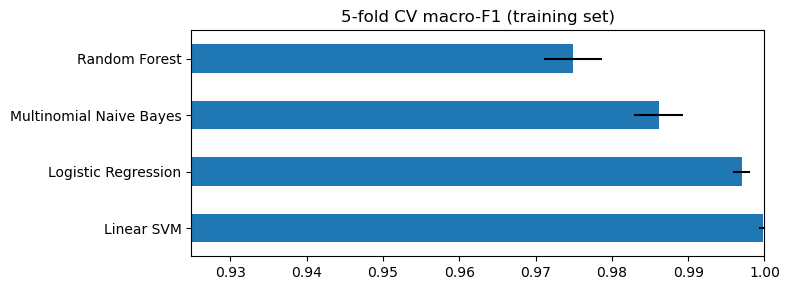

In [21]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Your code here
# We choose Option A. Resident descriptions are short (~4 words) and the
# category is mostly decided by a few material keywords ('bottle', 'cardboard',
# 'peel'), which TF-IDF + a linear model captures very well. It trains in
# seconds on CPU, is easy to interpret, and gives calibrated probabilities that
# the integrated assistant can use as a confidence score. A transformer would
# cost far more compute for little expected gain on text this simple.
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold


def make_text_pipeline(classifier):
    """TF-IDF (word uni+bigrams) followed by a classifier.

    The input is already lemmatized, so no extra preprocessor is needed here;
    vectorizer settings mirror tfidf_vectorizer from Part 1.3.
    """
    return Pipeline([
        ("tfidf", TfidfVectorizer(min_df=2, max_df=0.95, ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", classifier),
    ])


candidate_models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(C=5, max_iter=2000),
    "Linear SVM": LinearSVC(C=1.0),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

# Compare candidates with 5-fold stratified cross-validation on the TRAINING set
# only - the test set stays untouched until final evaluation.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, clf in candidate_models.items():
    scores = cross_val_score(make_text_pipeline(clf), X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:25s} macro-F1 = {scores.mean():.3f} ± {scores.std():.3f}")

cv_summary = pd.DataFrame({k: v for k, v in cv_results.items()}).agg(["mean", "std"]).T.sort_values("mean", ascending=False)
cv_summary["mean"].plot(kind="barh", xerr=cv_summary["std"], figsize=(8, 3), title="5-fold CV macro-F1 (training set)")
plt.xlim(cv_summary["mean"].min() - 0.05, 1.0)
plt.tight_layout()
plt.show()

### 3.3 Train and Evaluate the Model

Top hyper-parameter settings (CV macro-F1):


,param_tfidf__ngram_range,param_tfidf__min_df,param_clf__C,mean_train_score,mean_test_score
12,"(1, 1)",1,20,0.999939,0.998754
14,"(1, 1)",2,20,0.999939,0.998754
10,"(1, 1)",2,10,0.999758,0.998754
8,"(1, 1)",1,10,0.999758,0.998754
15,"(1, 2)",2,20,1.000000,0.998512
6,"(1, 1)",2,5,0.999758,0.998511
4,"(1, 1)",1,5,0.999758,0.998510
13,"(1, 2)",1,20,1.000000,0.998007


Best params: {'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)} | CV macro-F1 = 0.999


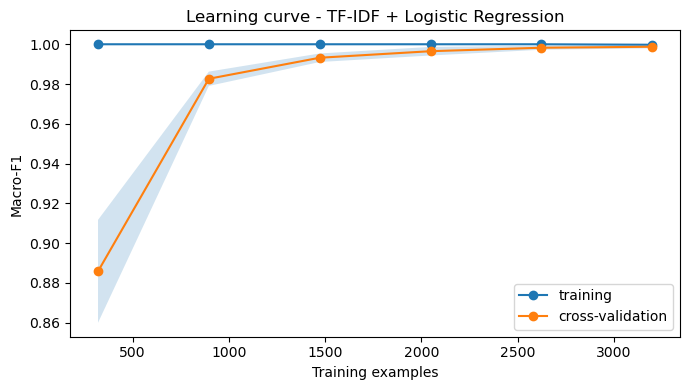

In [ ]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Your code here
from sklearn.model_selection import GridSearchCV, learning_curve

# Tune the regularisation strength and n-gram range of Logistic Regression.
# We use LR rather than the SVM even if their CV scores are close because it
# outputs probabilities directly
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "clf__C": [1, 5, 10, 20],
}
grid_search = GridSearchCV(
    make_text_pipeline(LogisticRegression(max_iter=2000)),
    param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True,
)
grid_search.fit(X_train, y_train)

grid_df = pd.DataFrame(grid_search.cv_results_)[
    ["param_tfidf__ngram_range", "param_tfidf__min_df", "param_clf__C", "mean_train_score", "mean_test_score"]
].sort_values("mean_test_score", ascending=False)
print("Top hyper-parameter settings (CV macro-F1):")
display(grid_df.head(8))
print(f"Best params: {grid_search.best_params_} | CV macro-F1 = {grid_search.best_score_:.3f}")

# The best pipeline is refitted on the full training set by GridSearchCV
text_model = grid_search.best_estimator_

# Monitor training progress: learning curve shows how validation performance
# grows with more data and whether the model over- or under-fits
train_sizes, train_scores, val_scores = learning_curve(
    text_model, X_train, y_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1,
)
plt.figure(figsize=(7, 4))
plt.plot(train_sizes, train_scores.mean(axis=1), "o-", label="training")
plt.plot(train_sizes, val_scores.mean(axis=1), "o-", label="cross-validation")
plt.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xlabel("Training examples")
plt.ylabel("Macro-F1")
plt.title("Learning curve - TF-IDF + Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

Test accuracy: 0.999 | macro-F1: 0.999

                     precision    recall  f1-score   support

          Cardboard      1.000     1.000     1.000       117
      Food Organics      1.000     1.000     1.000       104
              Glass      1.000     1.000     1.000       110
              Metal      0.990     1.000     0.995       101
Miscellaneous Trash      1.000     0.991     0.996       116
              Paper      1.000     1.000     1.000       101
            Plastic      1.000     1.000     1.000       114
      Textile Trash      1.000     1.000     1.000       117
         Vegetation      1.000     1.000     1.000       120

           accuracy                          0.999      1000
          macro avg      0.999     0.999     0.999      1000
       weighted avg      0.999     0.999     0.999      1000



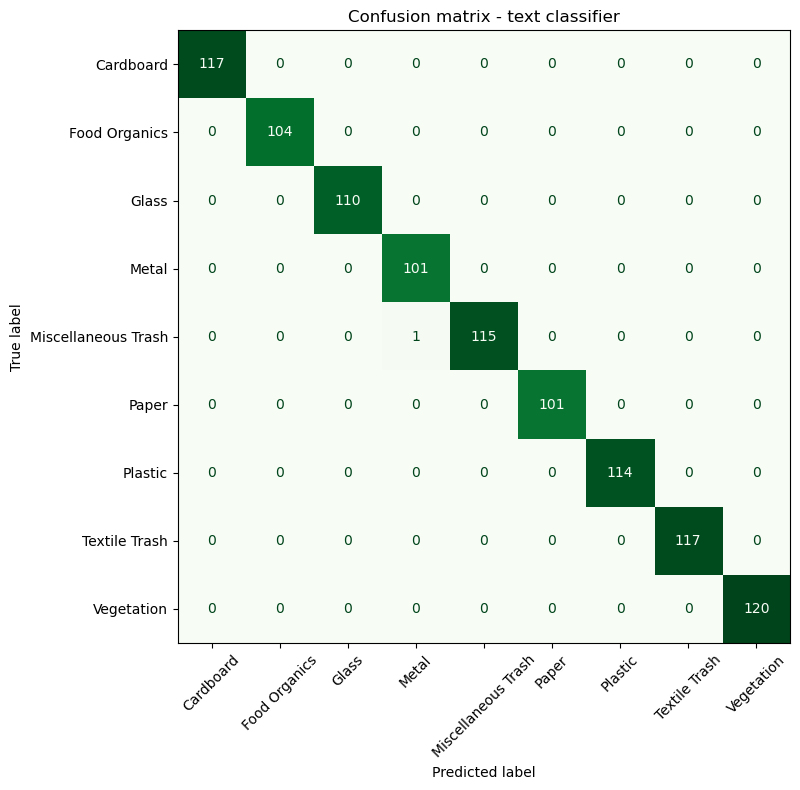

Misclassified: 1 / 1000

Most common confusions (true -> predicted):
true                 predicted
Miscellaneous Trash  Metal        1

Most confident mistakes:


,description,true,predicted,confidence
2589,crumpled metal Designer toy with product remai...,Miscellaneous Trash,Metal,0.467042


Most indicative terms per category:
  Cardboard              box, cardboard, packaging, sixpack, carton, roll
  Food Organics          peel, shell, bread, pit, scrap, bone
  Glass                  glass, bottle, light, bulb, perfume, champagne
  Metal                  metal, steel, tin, nail, cap, soda
  Miscellaneous Trash    cddvd, pencil, tape, battery, vacuum, pen
  Paper                  paper, notebook, envelope, newspaper, flyer, magazine
  Plastic                plastic, clamshell, container, bottle, toothbrush, cd
  Textile Trash          scarf, glove, rug, hat, curtain, tablecloth
  Vegetation             plant, weed, leaf, flower, branch, houseplant


In [ ]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_text_pred = text_model.predict(X_test)
text_classes = text_model.classes_
print(f"Test accuracy: {accuracy_score(y_test, y_text_pred):.3f} | "
      f"macro-F1: {f1_score(y_test, y_text_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_text_pred, digits=3))

cm_text = confusion_matrix(y_test, y_text_pred, labels=text_classes)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm_text, display_labels=text_classes).plot(ax=ax, cmap="Greens", xticks_rotation=45, colorbar=False)
ax.set_title("Confusion matrix - text classifier")
plt.tight_layout()
plt.show()

# Error analysis: look at the misclassified descriptions with their original
# wording and the dataset's 'common_confusion' note for the true category
errors = pd.DataFrame({
    "description": df.loc[X_test.index, "description"],
    "true": y_test,
    "predicted": y_text_pred,
    "confidence": text_model.predict_proba(X_test).max(axis=1),
})
errors = errors[errors["true"] != errors["predicted"]].sort_values("confidence", ascending=False)
print(f"Misclassified: {len(errors)} / {len(X_test)}")
print("\nMost common confusions (true -> predicted):")
print(errors.groupby(["true", "predicted"]).size().sort_values(ascending=False).head(8).to_string())
print("\nMost confident mistakes:")
display(errors.head(10))

# Words that drive each class (largest LR coefficients) - helps explain errors,
# e.g. shared words like 'container' or 'box' pull items across categories
vocab = text_model.named_steps["tfidf"].get_feature_names_out()
coefs = text_model.named_steps["clf"].coef_
print("Most indicative terms per category:")
for i, cat in enumerate(text_classes):
    print(f"  {cat:22s} {', '.join(vocab[coefs[i].argsort()[::-1][:6]])}")


### 3.4 Create Classification Function

In [24]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Your code here
    # Apply exactly the same preprocessing as the training data
    cleaned = advanced_preprocess(description)
    return text_model.predict([cleaned])[0]


def classify_waste_description_with_confidence(description):
    """Like classify_waste_description, but also returns the class probabilities.

    Returns:
        tuple: (predicted category, confidence, {category: probability})
    """
    probs = text_model.predict_proba([advanced_preprocess(description)])[0]
    best = int(np.argmax(probs))
    return text_model.classes_[best], float(probs[best]), dict(zip(text_model.classes_, probs.round(3)))


# Try it on new, unseen descriptions
for desc in ["empty wine bottle", "crushed soda can", "old pizza box with grease",
             "banana peel and coffee grounds", "torn cotton t-shirt", "broken phone charger",
             "pile of autumn leaves", "shredded office paper", "yogurt cup"]:
    cat, conf, _ = classify_waste_description_with_confidence(desc)
    print(f"{desc:32s} -> {cat:22s} (confidence {conf:.2f})")

# 'broken phone charger' gets a low confidence because none of its words are
# in the training vocabulary - the integrated assistant treats predictions
# below a confidence threshold as uncertain instead of trusting them blindly.

empty wine bottle                -> Glass                  (confidence 0.99)
crushed soda can                 -> Metal                  (confidence 0.95)
old pizza box with grease        -> Cardboard              (confidence 0.97)
banana peel and coffee grounds   -> Food Organics          (confidence 1.00)
torn cotton t-shirt              -> Textile Trash          (confidence 0.99)
broken phone charger             -> Vegetation             (confidence 0.22)
pile of autumn leaves            -> Vegetation             (confidence 1.00)
shredded office paper            -> Paper                  (confidence 1.00)
yogurt cup                       -> Plastic                (confidence 0.90)


## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [ ]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Your code here
import sys


sys.modules["triton"] = None

# This cell builds on Part 1 (df from 1.2, advanced_preprocess from 1.3 and
# policy_chunks from the RAG cell in 1.3) - fail early with a clear message
_missing = [name for name in ["df", "advanced_preprocess", "policy_chunks", "policy_df"] if name not in globals()]
if _missing:
    raise RuntimeError(f"Run the Part 1 cells first - missing: {', '.join(_missing)}")

import torch
import urllib.request
from pathlib import Path
from transformers import AutoTokenizer, AutoModel


extra_chunks = []
for cat, group in df.groupby("category"):
    tips = sorted(group["disposal_instruction"].dropna().unique())
    extra_chunks.append({"policy_type": "Resident Disposal Tips", "category": cat, "section": "Disposal Tips",
                         "text": f"Resident Disposal Tips ({cat}):\n" + "\n".join(f"- {t}" for t in tips)})
    confusions = sorted(group["common_confusion"].dropna().unique())
    if confusions:
        extra_chunks.append({"policy_type": "Resident Disposal Tips", "category": cat, "section": "Common Confusions",
                             "text": f"Common Confusions ({cat}):\n" + "\n".join(f"- {c}" for c in confusions)})

extra_df = pd.DataFrame(extra_chunks)
extra_df["jurisdiction"] = "Metro City"

chunks_df = pd.concat([pd.DataFrame(policy_chunks), extra_df], ignore_index=True)
chunks_df["chunk_id"] = range(len(chunks_df))
chunks_df["clean_text"] = chunks_df["text"].apply(advanced_preprocess)
print(f"Knowledge base: {len(chunks_df)} chunks "
      f"({len(policy_chunks)} policy sections + {len(extra_df)} disposal-tip chunks)")

# --- 2. Sparse embeddings (TF-IDF) --------------------------------------------
# Good at exact keyword matches such as 'aerosol', 'pizza box', 'batteries'
rag_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
chunk_tfidf = rag_vectorizer.fit_transform(chunks_df["clean_text"])


MODELS_DIR = Path("models")


def download_hf_model(repo_id, filenames):
    """Download a Hugging Face model's files into ./models/<name>; skips files already on disk."""
    local_dir = MODELS_DIR / repo_id.split("/")[-1]
    local_dir.mkdir(parents=True, exist_ok=True)
    for name in filenames:
        target = local_dir / name
        if target.exists():
            continue
        url = f"https://huggingface.co/{repo_id}/resolve/main/{name}"
        print(f"Downloading {url}...")
        tmp = target.with_suffix(target.suffix + ".part")
        with urllib.request.urlopen(url, timeout=120) as response, open(tmp, "wb") as f:
            while chunk := response.read(1 << 20):
                f.write(chunk)
        tmp.rename(target)
    return local_dir


embedder_path = download_hf_model(
    "sentence-transformers/all-MiniLM-L6-v2",
    ["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json", "special_tokens_map.json", "vocab.txt"],
)
embed_tokenizer = AutoTokenizer.from_pretrained(embedder_path)
embed_model = AutoModel.from_pretrained(embedder_path).eval()


def embed_texts(texts, batch_size=32):
    """Mean-pooled, L2-normalised MiniLM sentence embeddings (as used by sentence-transformers)."""
    vectors = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = embed_tokenizer(list(texts[i:i + batch_size]), padding=True, truncation=True,
                                    max_length=256, return_tensors="pt")
            token_embeddings = embed_model(**batch).last_hidden_state
            mask = batch["attention_mask"].unsqueeze(-1).float()
            pooled = (token_embeddings * mask).sum(1) / mask.sum(1)
            vectors.append(torch.nn.functional.normalize(pooled, dim=1).numpy())
    return np.vstack(vectors)


# Dense model sees the original text (it handles casing/stopwords itself)
chunk_dense = embed_texts(chunks_df["text"].tolist())
print(f"TF-IDF embeddings: {chunk_tfidf.shape} | dense embeddings: {chunk_dense.shape}")


# --- 4. Hybrid retriever ------------------------------------------------------
def retrieve_policy_chunks(query, category=None, top_k=5, alpha=0.5):
    """Return the top_k chunks by hybrid score = alpha*dense + (1-alpha)*tfidf.

    If a category is given (from the CNN / text classifier), the search is
    restricted to that category's chunks plus 'General' ones, so instructions
    for Glass can never be built from the Metal guidelines.
    """
    sparse = cosine_similarity(rag_vectorizer.transform([advanced_preprocess(query)]), chunk_tfidf).ravel()
    dense = chunk_dense @ embed_texts([query])[0]
    scores = alpha * dense + (1 - alpha) * sparse
    if category is not None:
        allowed = chunks_df["category"].isin([category, "General"]).values
        scores = np.where(allowed, scores, -np.inf)
    top_idx = scores.argsort()[::-1][:top_k]
    results = chunks_df.iloc[top_idx][["chunk_id", "policy_type", "category", "section", "text"]].copy()
    results["score"] = scores[top_idx]
    return results


# Compare sparse-only, dense-only and hybrid retrieval on paraphrased queries
# (no category hint, so the retriever has to find the right material itself)
for q in ["what do I do with an empty soda can", "where can I throw away dead batteries",
          "old jeans with holes", "grass clippings from my lawn"]:
    print(f"\nQuery: '{q}'")
    for a, label in [(0.0, "tfidf "), (1.0, "dense "), (0.5, "hybrid")]:
        top = retrieve_policy_chunks(q, top_k=1, alpha=a).iloc[0]
        print(f"  {label}: {top['policy_type']} | {top['section']} ({top['category']})")

Knowledge base: 85 chunks (67 policy sections + 18 disposal-tip chunks)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

TF-IDF embeddings: (85, 1184) | dense embeddings: (85, 384)

Query: 'what do I do with an empty soda can'
  tfidf : Resident Disposal Tips | Disposal Tips (Metal)
  dense : Resident Disposal Tips | Disposal Tips (Metal)
  hybrid: Resident Disposal Tips | Disposal Tips (Metal)

Query: 'where can I throw away dead batteries'
  tfidf : Resident Disposal Tips | Disposal Tips (Miscellaneous Trash)
  dense : Resident Disposal Tips | Disposal Tips (Miscellaneous Trash)
  hybrid: Resident Disposal Tips | Disposal Tips (Miscellaneous Trash)

Query: 'old jeans with holes'
  tfidf : Resident Disposal Tips | Disposal Tips (Textile Trash)
  dense : Resident Disposal Tips | Common Confusions (Textile Trash)
  hybrid: Resident Disposal Tips | Disposal Tips (Textile Trash)

Query: 'grass clippings from my lawn'
  tfidf : Community Recycling Program | VEGETATION GUIDELINES (Vegetation)
  dense : Community Recycling Program | VEGETATION GUIDELINES (Vegetation)
  hybrid: Community Recycling Program | VEG

### 4.2 Implement RAG-based System

In [ ]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Your code here
from transformers import AutoModelForCausalLM

llm_path = download_hf_model(
    "Qwen/Qwen2.5-0.5B-Instruct",
    ["config.json", "generation_config.json", "model.safetensors", "tokenizer.json",
     "tokenizer_config.json", "vocab.json", "merges.txt"],
)
llm_tokenizer = AutoTokenizer.from_pretrained(llm_path)
llm_model = AutoModelForCausalLM.from_pretrained(llm_path, dtype=torch.float32).eval()
print(f"Loaded {llm_path.name}: {sum(p.numel() for p in llm_model.parameters()) / 1e6:.0f}M parameters")

SYSTEM_PROMPT = (
    "You are the Metro City waste management assistant. Answer ONLY with information "
    "from the provided policy context. If the context does not cover something, do not invent it."
)


def build_rag_prompt(waste_category, retrieved, item_description=None):
    """Assemble the chat messages: retrieved policy context + the resident's request."""
    context = "\n\n".join(retrieved["text"])
    item = f"'{item_description}' ({waste_category})" if item_description else f"{waste_category} waste"
    user_msg = (
        f"Policy context:\n{context}\n\n"
        f"Write clear recycling instructions for a resident disposing of {item}. Use these headings:\n"
        "1. Bin / collection point\n2. How to prepare it\n3. Not accepted\n4. Tips\n"
        "Keep each point short."
    )
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_msg}]


def generate_text(messages, max_new_tokens=300, **gen_kwargs):
    """Run the chat model on a list of messages and return only the new text."""
    input_ids = llm_tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    with torch.no_grad():
        output = llm_model.generate(**input_ids, max_new_tokens=max_new_tokens,
                                    pad_token_id=llm_tokenizer.eos_token_id, **gen_kwargs)
    return llm_tokenizer.decode(output[0, input_ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()


def rag_answer(waste_category, item_description=None, top_k=6, **gen_kwargs):
    """Retrieve -> augment prompt -> generate. Returns (text, retrieved chunks)."""
    query = f"how to recycle and dispose of {item_description or waste_category}: bin, preparation, not accepted"
    retrieved = retrieve_policy_chunks(query, category=waste_category, top_k=top_k)
    answer = generate_text(build_rag_prompt(waste_category, retrieved, item_description), **gen_kwargs)
    return answer, retrieved


# Example: retrieved context and generated answer for one category
example_answer, example_chunks = rag_answer("Glass", do_sample=False)
print("Retrieved chunks:")
for _, r in example_chunks.iterrows():
    print(f"  [{r['score']:.2f}] {r['policy_type']} | {r['section']}")
print("\nGenerated instructions:\n" + example_answer)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loaded Qwen2.5-0.5B-Instruct: 494M parameters
Retrieved chunks:
  [0.46] Glass Recycling Guidelines | Preparation Instructions
  [0.45] Glass Recycling Guidelines | Collection Method
  [0.44] Glass Recycling Guidelines | Acceptable Items
  [0.43] Resident Disposal Tips | Common Confusions
  [0.42] Resident Disposal Tips | Disposal Tips
  [0.41] Glass Recycling Guidelines | Benefits

Generated instructions:
### Bin / Collection Point
- **Location:** Dedicated glass recycling bins located at designated locations within the city.

### How to Prepare It
- **Rinse Containers:** Fill containers with water and let them sit for at least 5 minutes to remove any residue or debris.
- **Remove Caps and Lids:** Carefully remove caps and lids from all containers, ensuring they are securely closed.
- **Label Containers:** Label containers clearly with their contents and date of recycling.

### Not Accepted
- **Broken Glass:** Do not recycle broken glass as it cannot be recycled indefinitely.
- **Drin

### 4.3 Adjust and Evaluate the System

In [ ]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Your code here

import time



def content_words(text):
    return set(advanced_preprocess(text).split())


def reference_text(category):
    """The category's own policy sections, used as the reference for coverage."""
    ref = chunks_df[(chunks_df["category"] == category) &
                    chunks_df["section"].isin(["Collection Method", "Preparation Instructions",
                                               "Non-Acceptable Items", "Items That Cannot Be Recycled",
                                               "Special Handling Items"])]
    return " ".join(ref["text"])


def score_answer(answer, retrieved, category):
    answer_words = content_words(answer)
    context_words = content_words(" ".join(retrieved["text"]))
    ref_words = content_words(reference_text(category))
    # Words from other category names mentioned in the answer hint at mixing up bins
    other_categories = [c for c in WASTE_CATEGORIES if c != category and c.lower() in answer.lower()]
    return {
        "groundedness": len(answer_words & context_words) / max(len(answer_words), 1),
        "coverage": len(answer_words & ref_words) / max(len(ref_words), 1),
        "other_categories_mentioned": len(other_categories),
        "words": len(answer.split()),
    }


decoding_configs = {
    "greedy": dict(do_sample=False, repetition_penalty=1.1),
    "beam search (3)": dict(do_sample=False, num_beams=3, repetition_penalty=1.1),
    "sampling T=0.3": dict(do_sample=True, temperature=0.3, top_p=0.9, repetition_penalty=1.1),
    "sampling T=0.7": dict(do_sample=True, temperature=0.7, top_p=0.9, repetition_penalty=1.1),
    "sampling T=1.2": dict(do_sample=True, temperature=1.2, top_p=0.95, repetition_penalty=1.1),
}
tuning_categories = ["Glass", "Cardboard", "Miscellaneous Trash"]   # one simple, one with caveats, one hazardous

tuning_rows = []
for config_name, gen_kwargs in decoding_configs.items():
    torch.manual_seed(42)
    for cat in tuning_categories:
        start = time.time()
        answer, retrieved = rag_answer(cat, **gen_kwargs)
        tuning_rows.append({"config": config_name, "category": cat, "seconds": time.time() - start,
                            **score_answer(answer, retrieved, cat), "answer": answer})

tuning_df = pd.DataFrame(tuning_rows)
tuning_summary = tuning_df.groupby("config", sort=False)[
    ["groundedness", "coverage", "other_categories_mentioned", "words", "seconds"]].mean().round(3)
display(tuning_summary)

# Pick the config with the best groundedness + coverage
best_config_name = (tuning_summary["groundedness"] + tuning_summary["coverage"]).idxmax()
RAG_GEN_CONFIG = decoding_configs[best_config_name]
print(f"Selected decoding config: {best_config_name} -> {RAG_GEN_CONFIG}")

# Show how temperature changes the text for the same category
for config_name in ["greedy", "sampling T=1.2"]:
    print(f"\n--- {config_name} (Cardboard) ---")
    print(tuning_df[(tuning_df["config"] == config_name) & (tuning_df["category"] == "Cardboard")]["answer"].iloc[0])

,groundedness,coverage,other_categories_mentioned,words,seconds
config,,,,,
greedy,0.315,0.559,1.333,191.667,47.919
beam search (3),0.767,0.585,0.667,92.000,50.801
sampling T=0.3,0.435,0.562,1.667,128.667,33.427
sampling T=0.7,0.370,0.536,1.333,157.667,39.831
sampling T=1.2,0.215,0.366,2.667,149.667,37.786


Selected decoding config: beam search (3) -> {'do_sample': False, 'num_beams': 3, 'repetition_penalty': 1.1}

--- greedy (Cardboard) ---
**Bin/Collection Point:**
- Place cardboard boxes in designated recycling bins or transport them to a local cardboard recycling center.

**How to Prepare It:**
- Remove any non-cardboard packaging.
- Flatten cardboard boxes to minimize space usage.
- Ensure the box is completely dry and clean before disposal.

**Not Accepted:**
- **Waxed cardboard:** This type should be discarded as it contains wax that can harm the environment.
- **Cardboard with food residue:** This could contain remnants of pastries, cakes, or other processed foods, which may pose health risks if ingested.
- **Cardboard with plastic liners:** These materials can cause damage to the recycling process and may need special handling.
- **Foam inserts:** These can interfere with the sorting system and may require additional steps during processing.
- **Packing peanuts:** These can also 

In [ ]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Your code here
eval_sample = df.loc[X_test.index].groupby("category", group_keys=False).sample(15, random_state=42)
hits_at_1, precision_at_3 = [], []
for _, row in eval_sample.iterrows():
    top = retrieve_policy_chunks(f"how do I dispose of {row['description']}", top_k=3)
    hits_at_1.append(top["category"].iloc[0] == row["category"])
    precision_at_3.append((top["category"] == row["category"]).mean())
print(f"Retrieval on {len(eval_sample)} test descriptions (no category hint): "
      f"hit@1 = {np.mean(hits_at_1):.3f} | precision@3 = {np.mean(precision_at_3):.3f}")

# 2. Generation quality for every category with the selected decoding config
eval_rows = []
for cat in WASTE_CATEGORIES:
    start = time.time()
    answer, retrieved = rag_answer(cat, **RAG_GEN_CONFIG)
    eval_rows.append({"category": cat, "seconds": time.time() - start,
                      "retrieved_on_topic": retrieved["category"].isin([cat, "General"]).mean(),
                      **score_answer(answer, retrieved, cat), "answer": answer})
generation_eval = pd.DataFrame(eval_rows)
display(generation_eval.drop(columns="answer").round(3))
print("Averages:")
print(generation_eval[["groundedness", "coverage", "other_categories_mentioned", "seconds"]].mean().round(3).to_string())

# 3. Item-specific instructions: the same category with a concrete item
for cat, item in [("Cardboard", "greasy pizza box"), ("Miscellaneous Trash", "used AA batteries")]:
    answer, _ = rag_answer(cat, item_description=item, **RAG_GEN_CONFIG)
    print(f"\n=== {item} ({cat}) ===\n{answer}")

# 4. Manual review: read a few answers against the policy text. Things to check:
#    - Is the bin correct? (e.g. Glass -> glass recycling bin)
#    - Are 'not accepted' items really from that category's Non-Acceptable list?
#    - Anything stated that is NOT in the context (hallucination)?
for cat in ["Glass", "Food Organics", "Textile Trash"]:
    print(f"\n=== {cat} ===\n{generation_eval.set_index('category').loc[cat, 'answer']}")

Retrieval on 135 test descriptions (no category hint): hit@1 = 0.630 | precision@3 = 0.607


,category,seconds,retrieved_on_topic,groundedness,coverage,other_categories_mentioned,words
0,Cardboard,38.427,1.0,0.788,0.812,1,79
1,Food Organics,71.427,1.0,0.943,0.484,0,70
2,Glass,46.912,1.0,0.828,0.441,0,76
3,Metal,65.314,1.0,0.853,0.676,0,146
4,Miscellaneous Trash,63.113,1.0,0.685,0.500,1,121
5,Paper,50.299,1.0,0.935,0.594,2,113
6,Plastic,42.273,1.0,0.974,0.714,0,77
7,Textile Trash,72.514,1.0,0.941,0.811,0,139
8,Vegetation,51.582,1.0,0.902,0.842,2,69


Averages:
groundedness                   0.872
coverage                       0.653
other_categories_mentioned     0.667
seconds                       55.762

=== greasy pizza box (Cardboard) ===
1. **Bin / Collection Point**: The resident should place the greasy pizza box in the community recycling program.

2. **How to Prepare It**: The resident should remove all non-cardboard packaging and flatten the box to save space.

3. **Not Acceptable**: The resident should not place the greasy pizza box in the community recycling program.

4. **Tips**: The resident should tear off any plastic, styrofoam, or metal parts before recycling.

=== used AA batteries (Miscellaneous Trash) ===
1. **Bin / collection point**: Take batteries to a dedicated collection point.
2. **How to prepare it**: Remove batteries from the AA battery holder.
3. **Not accepted**: Batteries are not recyclable.
4. **Tips**: Consider repairing or repurposing batteries before disposal.

=== Glass ===
1. **Bin / collection p

### 4.4 Create Instruction Generation Function

In [ ]:
# TODO: Create a function that takes a waste category and generates recycling instructions

_instruction_cache = {}


def generate_recycling_instructions(waste_category, item_description=None):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category
        item_description (str, optional): the specific item, for more targeted advice

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    # Your code here
    if waste_category not in WASTE_CATEGORIES:
        raise ValueError(f"Unknown waste category '{waste_category}'. Expected one of {WASTE_CATEGORIES}")

    # Greedy/beam decoding is deterministic, so category-level answers can be
    # cached - the assistant then only runs the LLM once per category
    cache_key = (waste_category, item_description)
    if cache_key in _instruction_cache:
        return _instruction_cache[cache_key]

    instructions, retrieved = rag_answer(waste_category, item_description=item_description, **RAG_GEN_CONFIG)
    relevant_docs = [
        {"policy": r["policy_type"], "section": r["section"], "category": r["category"],
         "score": round(float(r["score"]), 3), "text": r["text"]}
        for _, r in retrieved.iterrows()
    ]
    _instruction_cache[cache_key] = (instructions, relevant_docs)
    return instructions, relevant_docs


instructions, docs = generate_recycling_instructions("Plastic")
print(instructions)
print("\nSources:")
for d in docs:
    print(f"  - {d['policy']} | {d['section']} ({d['category']}, score {d['score']})")

1. Bin / collection point: Place plastic waste in dedicated recycling bins.
2. How to prepare it: Rinse containers, remove lids and caps, and check for recycling codes (1-7).
3. Not accepted: Plastic bags and film, polystyrene foam (code #6), containers with food residue, mixed material packaging, and black plastic containers.
4. Tips: Check recycling number on bottom and sort accordingly; if unmarked or non-recyclable, place in general waste; remove labels if possible; rinse container before recycling.

Sources:
  - Plastic Recycling Guidelines | Collection Method (Plastic, score 0.447)
  - Plastic Recycling Guidelines | Preparation Instructions (Plastic, score 0.434)
  - Resident Disposal Tips | Disposal Tips (Plastic, score 0.367)
  - Plastic Recycling Guidelines | Benefits (Plastic, score 0.352)
  - Plastic Recycling Guidelines | Non-Acceptable Items (Plastic, score 0.348)
  - Plastic Recycling Guidelines | Acceptable Items (Plastic, score 0.338)


## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [ ]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

# Your code here

assert set(class_names) == set(WASTE_CATEGORIES) == set(text_model.classes_), "category names must match"


class ImageWasteClassifier:
    """Wraps the Part 2 CNN. Accepts an image path, PIL image or HxWx3 array."""

    def __init__(self, model, class_names, image_size=(IMG_HEIGHT, IMG_WIDTH)):
        self.model, self.class_names, self.image_size = model, list(class_names), image_size

    def _to_batch(self, image):
        if isinstance(image, (str, Path)):
            image = keras.utils.load_img(image, target_size=self.image_size)
        array = tf.convert_to_tensor(np.asarray(image), dtype=tf.float32)
        if array.shape[:2] != self.image_size:
            array = tf.image.resize(array, self.image_size)
        # Raw [0, 255] pixels - EfficientNet does its own scaling (see Part 2.1)
        return tf.expand_dims(array, 0)

    def predict(self, image, top_k=3):
        probs = self.model.predict(self._to_batch(image), verbose=0)[0]
        order = np.argsort(probs)[::-1][:top_k]
        top = [(self.class_names[i], float(probs[i])) for i in order]
        return top[0][0], top[0][1], top


class TextWasteClassifier:
    """Wraps the Part 3 text pipeline (same preprocessing as training)."""

    def __init__(self, model):
        self.model = model

    def predict(self, description, top_k=3):
        probs = self.model.predict_proba([advanced_preprocess(description)])[0]
        order = np.argsort(probs)[::-1][:top_k]
        top = [(self.model.classes_[i], float(probs[i])) for i in order]
        return top[0][0], top[0][1], top


class RecyclingInstructionGenerator:
    """Wraps the Part 4 RAG function."""

    def generate(self, category, item_description=None):
        return generate_recycling_instructions(category, item_description=item_description)


# Use the CNN trained in Part 2 if it is in memory, otherwise load the saved model
if "cnn_model" not in globals():
    cnn_model = keras.models.load_model("waste_cnn_final.keras")

image_classifier = ImageWasteClassifier(cnn_model, class_names)
text_classifier = TextWasteClassifier(text_model)
instruction_generator = RecyclingInstructionGenerator()

# Below these confidences the assistant warns the resident instead of trusting
# the label. Text is stricter because the text model is near-certain on known
# vocabulary, so a low score almost always means unseen words.
CONFIDENCE_THRESHOLDS = {"image": 0.50, "text": 0.60}
print("Components ready:", type(image_classifier).__name__, type(text_classifier).__name__,
      type(instruction_generator).__name__)

Components ready: ImageWasteClassifier TextWasteClassifier RecyclingInstructionGenerator


### 5.2 Implement Integrated Assistant

Category: Glass (confidence 98%) via text
Top predictions: Glass 98%, Metal 0%, Miscellaneous Trash 0%

1. Bin / collection point: Glass Jam Jar with Lid

2. How to prepare it:
   - Rinse the container thoroughly.
   - Remove the cap and lid (recycle separately).
   - Label the container clearly.

3. Not accepted:
   - Broken glass should be wrapped and labeled before disposal.
   - Non-container glass may require special disposal.

4. Tips:
   - Place in glass recycling bin, sorted by color if required.
   - Remove caps, lids, and corks before recycling.
   - Rinse container before recycling.

Sources: Glass Recycling Guidelines - Preparation Instructions; Glass Recycling Guidelines - Acceptable Items; Resident Disposal Tips - Disposal Tips; Residential Recycling Rules - GLASS GUIDELINES; Glass Recycling Guidelines - Collection Method; Resident Disposal Tips - Common Confusions
(40.85s)




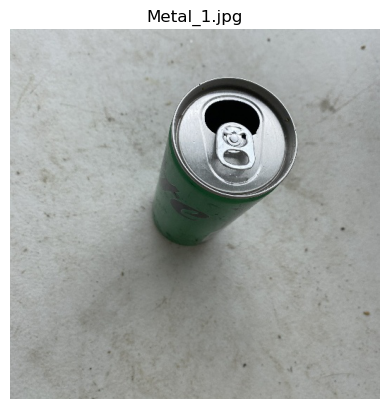

Category: Plastic (confidence 18%) via image
Top predictions: Plastic 18%, Miscellaneous Trash 15%, Cardboard 13%

1. Bin / collection point: Place plastic waste in dedicated recycling bins.
2. How to prepare it: Rinse containers, remove lids and caps, and check for recycling codes (1-7).
3. Not accepted: Plastic bags and film, polystyrene foam (code #6), containers with food residue, mixed material packaging, and black plastic containers.
4. Tips: Check recycling number on bottom and sort accordingly; if unmarked or non-recyclable, place in general waste; remove labels if possible; rinse container before recycling.

Sources: Plastic Recycling Guidelines - Collection Method; Plastic Recycling Guidelines - Preparation Instructions; Resident Disposal Tips - Disposal Tips; Plastic Recycling Guidelines - Benefits; Plastic Recycling Guidelines - Non-Acceptable Items; Plastic Recycling Guidelines - Acceptable Items
(1.5s)


In [31]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image", generate_instructions=True):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"
        generate_instructions (bool): set False to only classify (used for fast evaluation)

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Your code here
    start = time.time()

    # 1. Route the input to the matching classifier
    if input_type == "image":
        category, confidence, top_predictions = image_classifier.predict(input_data)
        item_description = None
    elif input_type == "text":
        if not isinstance(input_data, str) or not input_data.strip():
            raise ValueError("Text input must be a non-empty description")
        category, confidence, top_predictions = text_classifier.predict(input_data)
        item_description = input_data.strip()
    else:
        raise ValueError(f"input_type must be 'image' or 'text', got '{input_type}'")

    result = {
        "input_type": input_type,
        "category": category,
        "confidence": round(confidence, 3),
        "top_predictions": [(c, round(p, 3)) for c, p in top_predictions],
        "low_confidence": confidence < CONFIDENCE_THRESHOLDS[input_type],
        "instructions": None,
        "sources": [],
    }

    # 2. Warn on uncertain predictions rather than giving confident wrong advice
    if result["low_confidence"]:
        alternatives = ", ".join(c for c, _ in top_predictions[1:])
        result["warning"] = (f"Not sure this is {category} (confidence {confidence:.0%}). It could also be: "
                             f"{alternatives}. Check the item, or try a "
                             f"{'text description' if input_type == 'image' else 'photo'}.")

    # 3. Generate policy-grounded instructions for the predicted category
    if generate_instructions:
        instructions, docs = instruction_generator.generate(category, item_description)
        result["instructions"] = instructions
        result["sources"] = [f"{d['policy']} - {d['section']}" for d in docs]

    result["processing_seconds"] = round(time.time() - start, 2)
    return result


def print_assistant_result(result):
    """Human-readable view of the assistant's output."""
    print(f"Category: {result['category']} (confidence {result['confidence']:.0%}) via {result['input_type']}")
    print("Top predictions:", ", ".join(f"{c} {p:.0%}" for c, p in result["top_predictions"]))
    if result.get("warning"):
        print("WARNING:", result["warning"])
    if result["instructions"]:
        print("\n" + result["instructions"])
        print("\nSources:", "; ".join(result["sources"]))
    print(f"({result['processing_seconds']}s)")


# Demo with a text description and an image file from the dataset
print_assistant_result(waste_management_assistant("empty glass jam jar with lid", input_type="text"))
print("\n" + "=" * 80 + "\n")
demo_image_path = sorted((data_dir / "Metal").glob("*.jpg"))[0]
plt.imshow(keras.utils.load_img(demo_image_path))
plt.axis("off")
plt.title(demo_image_path.name)
plt.show()
print_assistant_result(waste_management_assistant(str(demo_image_path), input_type="image"))

### 5.3 Evaluate the Integrated System

In [ ]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Your code here
# Prerequisites: test_images / test_labels come from Part 2.1. The true image
# labels are recomputed here so this cell does not depend on having run the
# Part 2 evaluation cell.
if "test_images" not in globals():
    raise RuntimeError("Run Part 2.1 first - it builds test_images / test_labels")
y_test_true = np.argmax(test_labels, axis=1)

# 1. Classification accuracy of the full pipeline (instructions switched off so
#    the whole test sets can be processed quickly)
image_results = [waste_management_assistant(img, "image", generate_instructions=False) for img in test_images]
image_eval = pd.DataFrame({
    "true": [class_names[i] for i in y_test_true],
    "predicted": [r["category"] for r in image_results],
    "confidence": [r["confidence"] for r in image_results],
    "low_confidence": [r["low_confidence"] for r in image_results],
})

text_test_df = df.loc[X_test.index]
text_results = [waste_management_assistant(d, "text", generate_instructions=False) for d in text_test_df["description"]]
text_eval = pd.DataFrame({
    "true": text_test_df["category"].values,
    "predicted": [r["category"] for r in text_results],
    "confidence": [r["confidence"] for r in text_results],
    "low_confidence": [r["low_confidence"] for r in text_results],
})


def summarise(eval_df, name):
    correct = eval_df["true"] == eval_df["predicted"]
    confident = ~eval_df["low_confidence"]
    return {
        "input": name,
        "n": len(eval_df),
        "accuracy": correct.mean(),
        "flagged_low_confidence": (~confident).mean(),
        # Accuracy on the answers the assistant is confident about, and how
        # many of its mistakes were caught by the confidence check
        "accuracy_when_confident": correct[confident].mean() if confident.any() else np.nan,
        "errors_flagged": (~confident[~correct]).mean() if (~correct).any() else np.nan,
        "top3_accuracy": np.mean([t in [c for c, _ in r["top_predictions"]]
                                  for t, r in zip(eval_df["true"], results_by_name[name])]),
    }


results_by_name = {"image": image_results, "text": text_results}
system_summary = pd.DataFrame([summarise(image_eval, "image"), summarise(text_eval, "text")]).set_index("input")
display(system_summary.round(3))

# Per-category accuracy side by side: which materials are hard for which input?
per_category = pd.DataFrame({
    "image_accuracy": image_eval.assign(ok=image_eval["true"] == image_eval["predicted"]).groupby("true")["ok"].mean(),
    "text_accuracy": text_eval.assign(ok=text_eval["true"] == text_eval["predicted"]).groupby("true")["ok"].mean(),
})
per_category.plot(kind="barh", figsize=(8, 5), title="Pipeline accuracy per category")
plt.xlabel("Accuracy")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

# 2. End-to-end runs with instruction generation on a few test cases: one test
#    image per category plus some text descriptions, with timing
rng = np.random.default_rng(42)
end_to_end = []
for cat_idx, cat in enumerate(class_names):
    idx = rng.choice(np.where(y_test_true == cat_idx)[0])
    r = waste_management_assistant(test_images[idx], "image")
    end_to_end.append({"input": "image", "true": cat, **{k: r[k] for k in ["category", "confidence", "low_confidence", "processing_seconds"]},
                       "correct": r["category"] == cat})
for desc in ["broken umbrella", "aluminium foil tray with food residue", "stack of old magazines", "wilted flowers"]:
    r = waste_management_assistant(desc, "text")
    end_to_end.append({"input": "text", "true": desc, **{k: r[k] for k in ["category", "confidence", "low_confidence", "processing_seconds"]}})
display(pd.DataFrame(end_to_end))

# 3. Full output for an uncertain case, to show the warning path
print_assistant_result(waste_management_assistant("broken phone charger", "text"))

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.